<a href="https://colab.research.google.com/github/preethikamanokaran/EDA-Project/blob/main/Exploratory_Data_Analysis_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

from IPython.display import display

# Create a folder for project files
os.makedirs("eda_project/plots", exist_ok=True)

# Load the dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

# Display the first five rows
print("FIRST FIVE ROWS")
display(df.head())

# Display dataset information
print("\nDATASET SHAPE:", df.shape)
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE ROWS:", df.duplicated().sum())

FIRST FIVE ROWS


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4



DATASET SHAPE: (244, 7)

COLUMN NAMES:
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']

DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB

MISSING VALUES
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

DUPLICATE ROWS: 1


In [2]:
# Create a copy for analysis
data = df.copy()

# Remove duplicate rows
data = data.drop_duplicates()

# Fill missing numeric values with their column median
numeric_cols = data.select_dtypes(include="number").columns
data[numeric_cols] = data[numeric_cols].fillna(
    data[numeric_cols].median()
)

# Fill missing categorical values with the most frequent value
categorical_cols = data.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    if data[col].isnull().any():
        data[col] = data[col].fillna(
            data[col].mode().iloc[0]
        )

print("CLEANED DATA SHAPE:", data.shape)

# Statistical summary
print("\nSTATISTICAL SUMMARY")
display(data.describe().round(2))

# Average values by day
print("\nAVERAGE BILL AND TIP BY DAY")
display(
    data.groupby("day")[["total_bill", "tip"]]
    .mean()
    .round(2)
)

# Average tip by dining time
print("\nAVERAGE TIP BY DINING TIME")
display(
    data.groupby("time")["tip"]
    .mean()
    .round(2)
)

# Correlation between numerical variables
print("\nCORRELATION MATRIX")
display(data[numeric_cols].corr().round(2))

CLEANED DATA SHAPE: (243, 7)

STATISTICAL SUMMARY


,total_bill,tip,size
count,243.00,243.00,243.00
mean,19.81,3.00,2.57
std,8.91,1.39,0.95
min,3.07,1.00,1.00
25%,13.38,2.00,2.00
50%,17.81,2.92,2.00
75%,24.17,3.58,3.00
max,50.81,10.00,6.00



AVERAGE BILL AND TIP BY DAY


,total_bill,tip
day,,
Fri,17.15,2.73
Sat,20.44,2.99
Sun,21.41,3.26
Thur,17.76,2.78



AVERAGE TIP BY DINING TIME


,tip
time,
Dinner,3.10
Lunch,2.74



CORRELATION MATRIX


,total_bill,tip,size
total_bill,1.00,0.67,0.60
tip,0.67,1.00,0.49
size,0.60,0.49,1.00


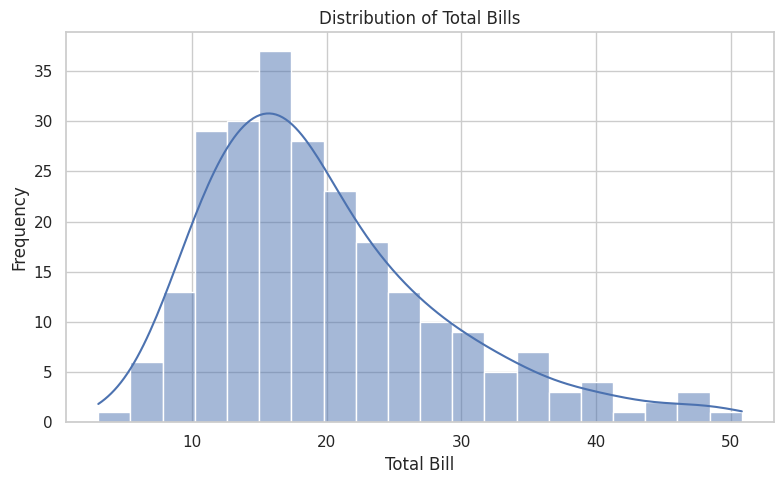

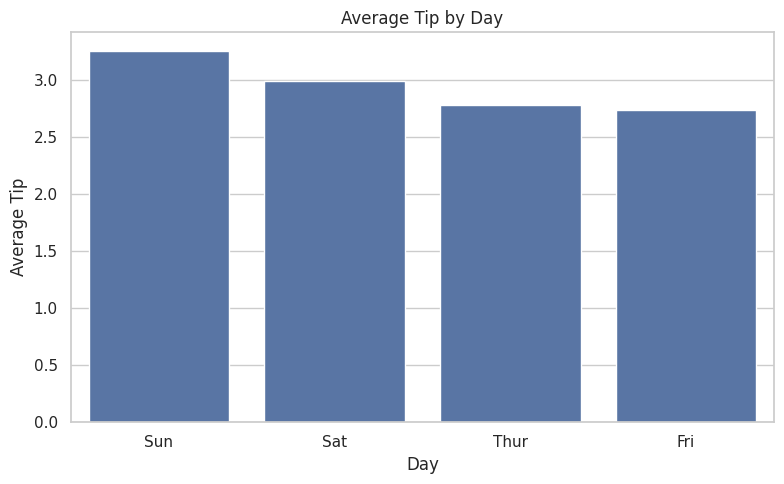

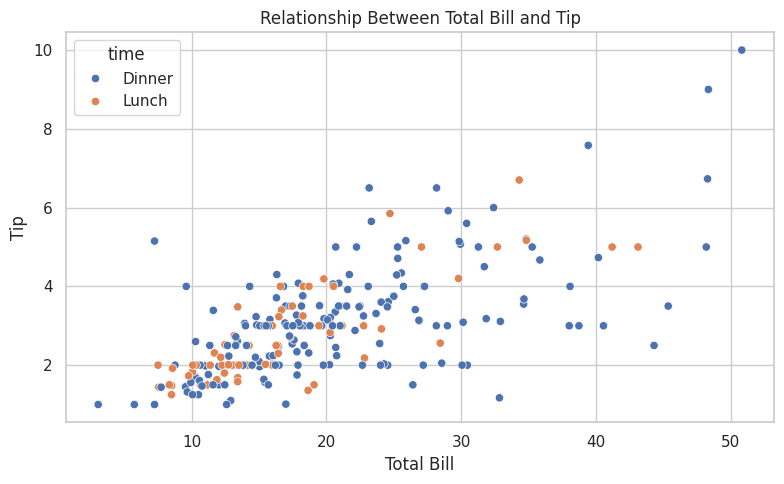

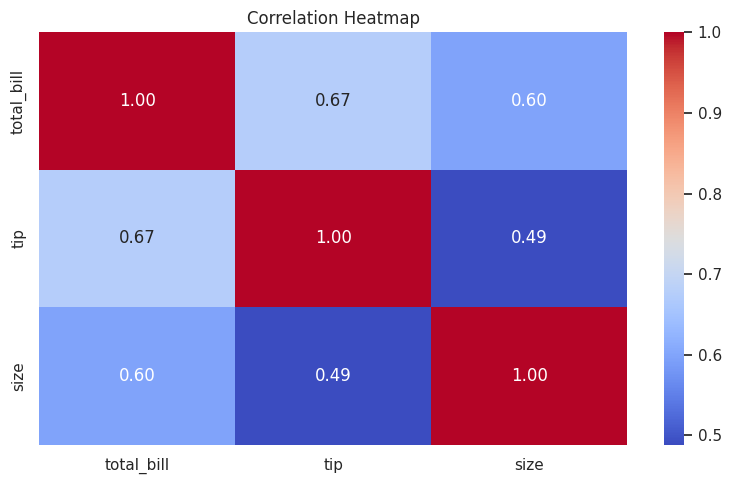

In [4]:
sns.set_theme(style="whitegrid")

# 1. Distribution of total bills
plt.figure(figsize=(8, 5))
sns.histplot(data=data, x="total_bill", bins=20, kde=True)
plt.title("Distribution of Total Bills")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("eda_project/plots/01_bill_distribution.png")
plt.show()

# 2. Average tip by day
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x="day", y="tip", errorbar=None)
plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip")
plt.tight_layout()
plt.savefig("eda_project/plots/02_average_tip_by_day.png")
plt.show()

# 3. Relationship between bill and tip
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="total_bill",
    y="tip",
    hue="time"
)
plt.title("Relationship Between Total Bill and Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.tight_layout()
plt.savefig("eda_project/plots/03_bill_vs_tip.png")
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    data[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("eda_project/plots/04_correlation_heatmap.png")
plt.show()

In [5]:
# Save cleaned dataset
data.to_csv("eda_project/cleaned_data.csv", index=False)

# Save statistical summary
data.describe().round(2).to_csv(
    "eda_project/statistical_summary.csv"
)

# Calculate key findings from the dataset
average_bill = data["total_bill"].mean()
average_tip = data["tip"].mean()
correlation = data["total_bill"].corr(data["tip"])

day_tips = data.groupby("day")["tip"].mean()
best_day = day_tips.idxmax()

time_tips = data.groupby("time")["tip"].mean()
best_time = time_tips.idxmax()

# Display findings
print("KEY FINDINGS")
print(f"Average total bill: {average_bill:.2f}")
print(f"Average tip: {average_tip:.2f}")
print(f"Bill-tip correlation: {correlation:.2f}")
print(f"Day with highest average tip: {best_day}")
print(f"Dining time with highest average tip: {best_time}")

# Create a structured project report
report = f"""
# Exploratory Data Analysis (EDA) Report

## 1. Introduction
This project explores a restaurant tips dataset using Python.
The objective is to discover patterns, trends, and relationships
in restaurant bills and tips.

## 2. Dataset Description
- Original number of rows: {len(df)}
- Number of rows after cleaning: {len(data)}
- Number of columns: {data.shape[1]}
- Main variables: total_bill, tip, sex, smoker, day, time, size

## 3. Data Cleaning
Duplicate rows were removed.
Missing numerical values were filled with their column median.
Missing categorical values were filled with their most frequent value.

## 4. Statistical Findings
- Average total bill: {average_bill:.2f}
- Average tip: {average_tip:.2f}
- Correlation between bill and tip: {correlation:.2f}
- Day with highest average tip: {best_day}
- Dining time with highest average tip: {best_time}

## 5. Visualizations
Four visualizations were generated:
1. Distribution of total bills
2. Average tip by day
3. Relationship between total bill and tip
4. Correlation heatmap

## 6. Conclusion
The analysis summarizes restaurant bills and tipping patterns.
The correlation value describes the direction and strength of the
linear relationship between bills and tips. These findings describe
this dataset and do not prove that one factor causes another.
"""

with open("eda_project/EDA_Report.md", "w", encoding="utf-8") as f:
    f.write(report)

# Create a README file
readme = """
# Exploratory Data Analysis (EDA) Project

## Objective
Explore a restaurant tips dataset to discover patterns and trends.

## Tools Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Google Colab

## Project Files
- EDA_Project.ipynb: Analysis notebook (upload separately)
- cleaned_data.csv: Cleaned dataset
- statistical_summary.csv: Statistical summary
- EDA_Report.md: Findings and conclusion
- plots/: Generated charts

## How to Run
Open EDA_Project.ipynb in Google Colab and run the cells in order.

## Dataset
https://github.com/mwaskom/seaborn-data/blob/master/tips.csv
"""

with open("eda_project/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# Package all generated files into one ZIP
with zipfile.ZipFile(
    "EDA_Project_Files.zip", "w", zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, files in os.walk("eda_project"):
        for filename in files:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, arcname=filepath)

print("\nPROJECT FILES CREATED SUCCESSFULLY!")
print("EDA_Project_Files.zip contains your report, data and charts.")

# Download the ZIP to your device
from google.colab import files
files.download("EDA_Project_Files.zip")

KEY FINDINGS
Average total bill: 19.81
Average tip: 3.00
Bill-tip correlation: 0.67
Day with highest average tip: Sun
Dining time with highest average tip: Dinner

PROJECT FILES CREATED SUCCESSFULLY!
EDA_Project_Files.zip contains your report, data and charts.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>